### Importing library 

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np 
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, f1_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

### Handling missing values 

In [2]:
df = pd.read_csv("loan_approval_data.csv")
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

In [4]:
df.isnull().sum()

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [5]:
df.describe()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [6]:
categorical_cols = df.select_dtypes("object").columns
numerical_cols = df.select_dtypes(include=["float64"]).columns
numerical_cols

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='object')

In [7]:
num_imp = SimpleImputer(strategy="mean")
cat_imp = SimpleImputer(strategy="most_frequent")

df[numerical_cols] = num_imp.fit_transform(df[numerical_cols])
df[categorical_cols] = cat_imp.fit_transform(df[categorical_cols])

### EDA

[]

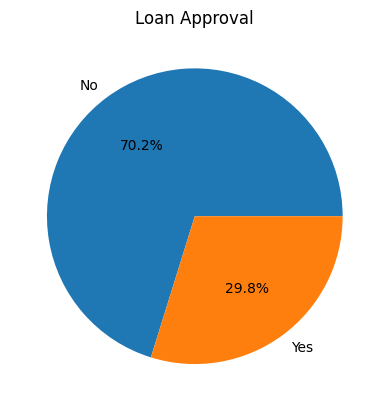

In [8]:
classes_count = df["Loan_Approved"].value_counts()
plt.pie(classes_count, labels=["No", "Yes"], autopct="%1.1f%%")
plt.title("Loan Approval")
plt.plot()

[Text(0, 0, '621'), Text(0, 0, '379')]

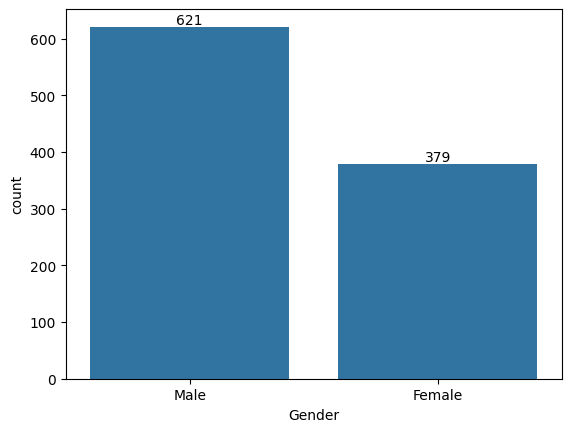

In [9]:
gender_cnt = df["Gender"].value_counts()
ax = sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '722'), Text(0, 0, '278')]

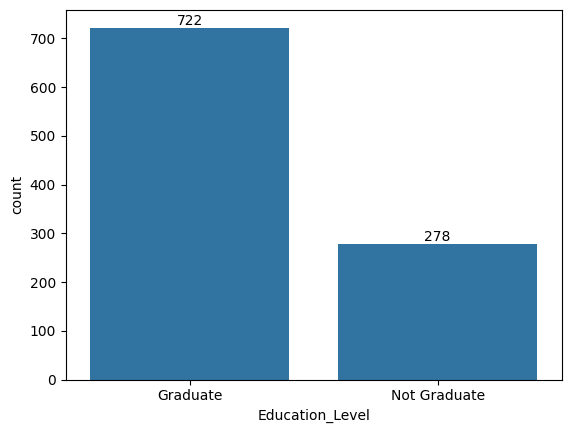

In [10]:
edu_cnt = df["Education_Level"].value_counts()
ax = sns.barplot(edu_cnt)
ax.bar_label(ax.containers[0])

In [11]:
categorical_cols

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')

[]

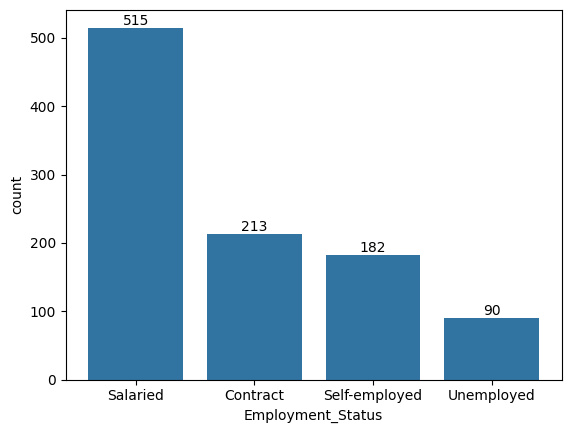

In [12]:
emp_status = df["Employment_Status"].value_counts()
ax = sns.barplot(emp_status)
ax.bar_label(ax.containers[0])
ax.plot()

[]

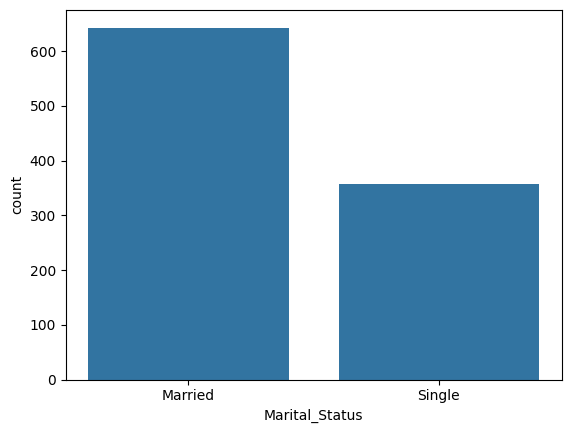

In [13]:
marriage_cnt = df["Marital_Status"].value_counts()
ax = sns.barplot(marriage_cnt)
ax.plot()

[]

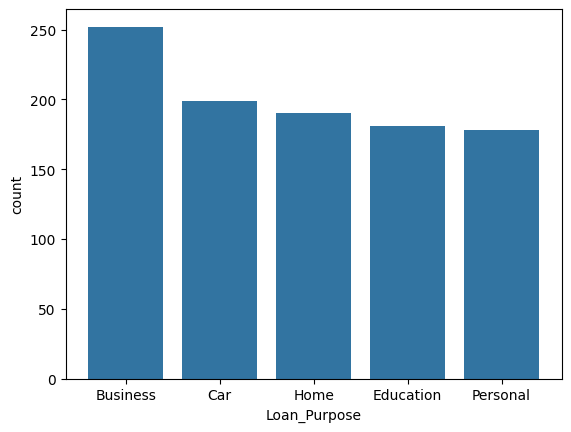

In [14]:
loan_Purpose_cnt = df["Loan_Purpose"].value_counts()
ax = sns.barplot(loan_Purpose_cnt)
ax.plot()

[]

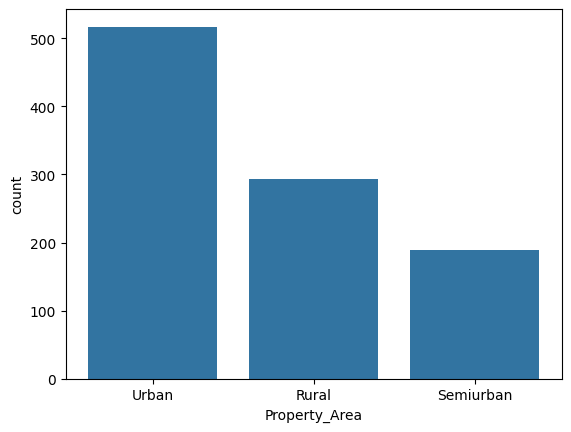

In [15]:
property = df["Property_Area"].value_counts()
ax = sns.barplot(property)
ax.plot()

[]

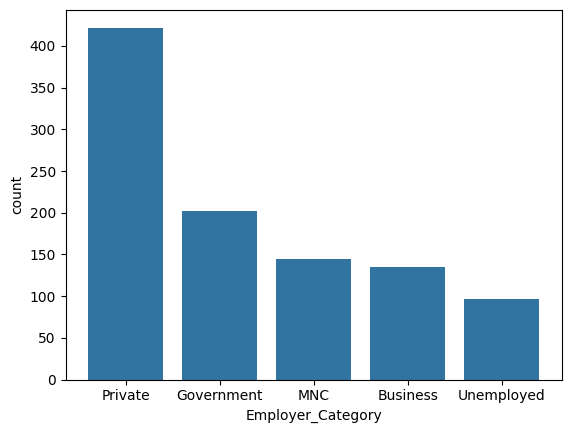

In [16]:
emp_cat = df["Employer_Category"].value_counts()
ax = sns.barplot(emp_cat)
ax.plot()

<Axes: xlabel='Applicant_Income', ylabel='Count'>

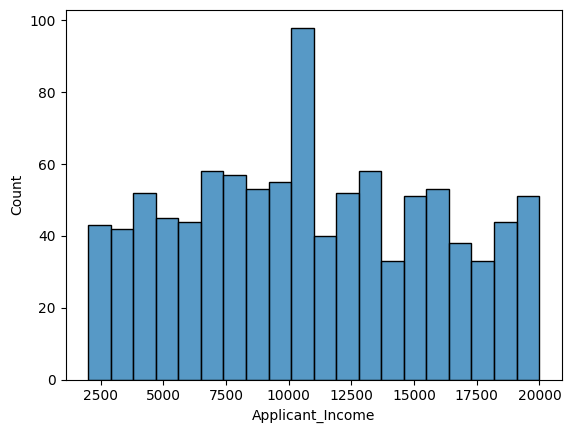

In [17]:
sns.histplot(
    data=df,
    x="Applicant_Income",
    bins=20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

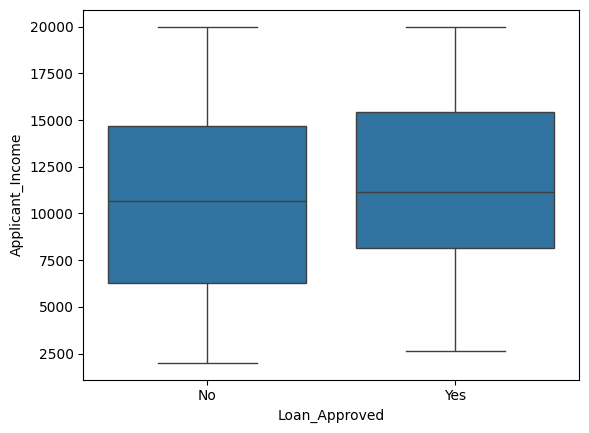

In [18]:
sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="Applicant_Income"
)

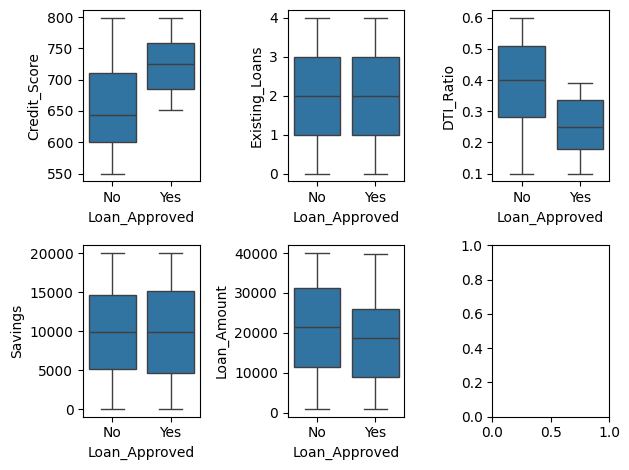

In [19]:
fig, axes = plt.subplots(2, 3)

sns.boxplot(ax = axes[0, 0], data=df, x="Loan_Approved", y="Credit_Score")
sns.boxplot(ax = axes[0, 1], data=df, x="Loan_Approved", y="Existing_Loans")
sns.boxplot(ax = axes[0, 2], data=df, x="Loan_Approved", y="DTI_Ratio")
sns.boxplot(ax = axes[1, 0], data=df, x="Loan_Approved", y="Savings")
sns.boxplot(ax = axes[1, 1], data=df, x="Loan_Approved", y="Loan_Amount")
# sns.boxplot(axes[1, 2], data=df, x="Loan_Approved", y="Savings")

plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

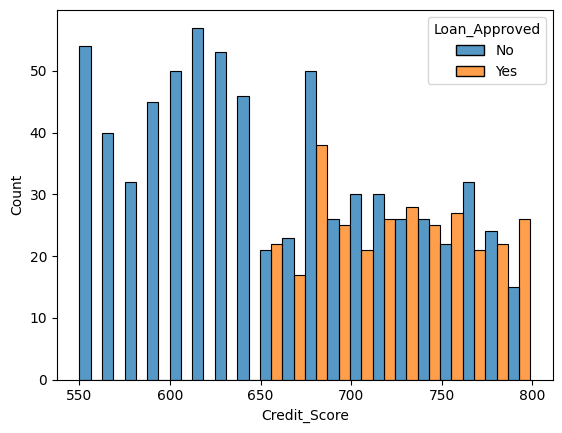

In [20]:
sns.histplot(
    data=df,
    x="Credit_Score",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)

<Axes: xlabel='Applicant_Income', ylabel='Count'>

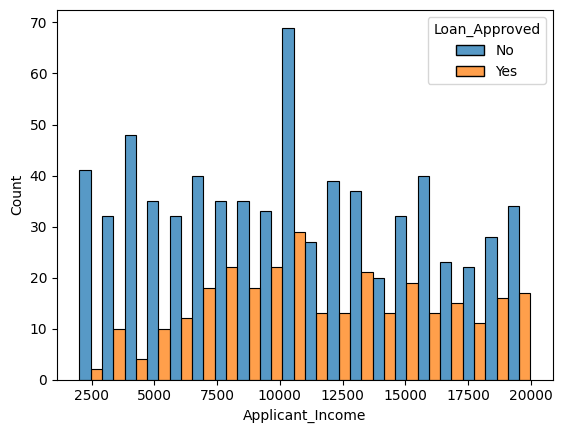

In [21]:
sns.histplot(
    data=df,
    x="Applicant_Income",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)

<Axes: xlabel='Credit_Score', ylabel='Applicant_Income'>

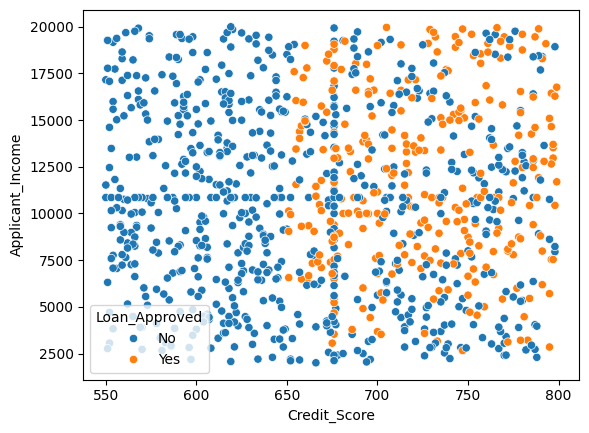

In [22]:
sns.scatterplot(
    data=df,
    x="Credit_Score",
    y="Applicant_Income",
    hue="Loan_Approved"
)

In [23]:
df = df.drop(columns="Applicant_ID")
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


### Feature Encoding

In [24]:
df.columns

Index(['Applicant_Income', 'Coapplicant_Income', 'Employment_Status', 'Age',
       'Marital_Status', 'Dependents', 'Credit_Score', 'Existing_Loans',
       'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term',
       'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender',
       'Employer_Category', 'Loan_Approved'],
      dtype='object')

In [25]:
le = LabelEncoder()
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])
df["Education_Level"] = le.fit_transform(df["Education_Level"])

df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [26]:
one_hot_cols = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Gender", "Employer_Category"]
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")


In [27]:
encoded = ohe.fit_transform(df[one_hot_cols])
encoded_df = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(one_hot_cols), index=df.index)
df = pd.concat([df.drop(columns=one_hot_cols), encoded_df], axis=1)
df.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Education_Level                  1000 non-null   int64  
 12  Loan_Approved        

### Correlation Heapmap

In [29]:
nums_cols = df.select_dtypes(include=["number"])
corr_matrix = nums_cols.corr()
corr_matrix["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

<Axes: >

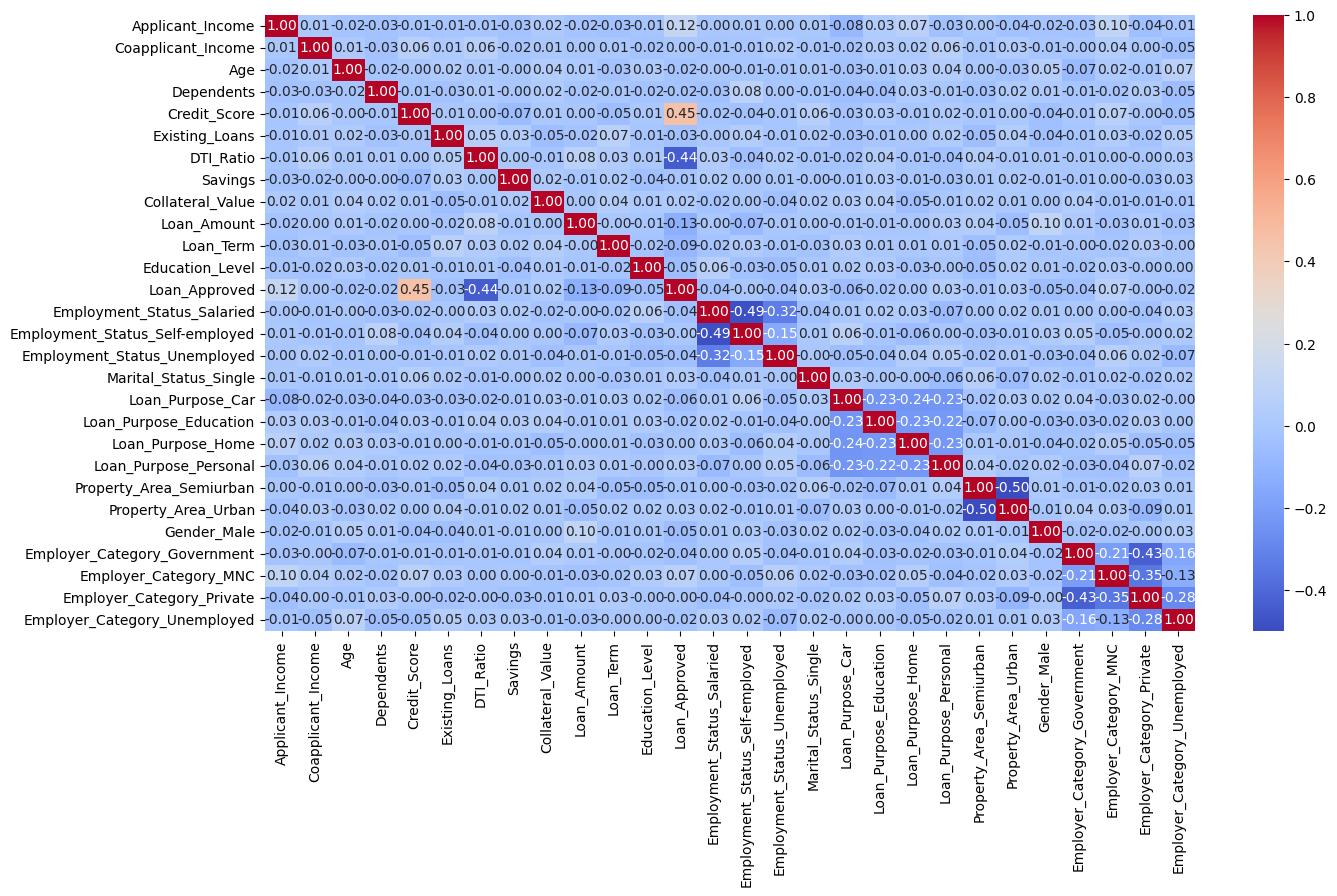

In [30]:
plt.figure(figsize=(15, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)


### Train-Test-Split & Feature Selection

In [31]:
X = df.drop(columns=["Loan_Approved"])
y = df["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Model Training

#### Logistic Regression

In [32]:
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression())
])

param_grid = [
    {
        # lbfgs, sag, and newton-cg ONLY support l2 or None
        'logistic__penalty': ["l2", None],
        'logistic__C': [0.0001, 0.01, 0.1, 1, 10, 100],
        'logistic__solver': ["lbfgs", "sag", "newton-cg"],
        'logistic__max_iter': [1000, 2000, 3000]
    },
    {
        # liblinear supports l1 and l2 (but not None)
        'logistic__penalty': ["l1", "l2"],
        'logistic__C': [0.0001, 0.01, 0.1, 1, 10, 100],
        'logistic__solver': ["liblinear"],
        'logistic__max_iter': [1000, 2000, 3000]
    },
    {
        # saga supports everything, including elasticnet (needs l1_ratio to work)
        'logistic__penalty': ["l1", "l2", "elasticnet", None],
        'logistic__l1_ratio': [0.5], # Required if elasticnet is chosen
        'logistic__C': [0.0001, 0.01, 0.1, 1, 10, 100],
        'logistic__solver': ["saga"],
        'logistic__max_iter': [1000, 2000, 3000]
    }
]

classiferCV = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring=["accuracy", "precision", "recall", "f1"],
    refit="f1",
    cv=5
)

classiferCV.fit(X_train, y_train)

y_pred = classiferCV.predict(X_test)

print("Accuracy:\t", accuracy_score(y_test, y_pred))
print("Recall:\t",  recall_score(y_test, y_pred))
print("Precision:\t", precision_score(y_test, y_pred))
print("F1 Scorce:\t", f1_score(y_test, y_pred))
print("CM:\n", confusion_matrix(y_test, y_pred))

res = pd.DataFrame(classiferCV.cv_results_)
# print(res[["knn__param_n_neighbors", "mean_test_score"]])

print(classiferCV.best_params_)

c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 ins

Accuracy:	 0.87
Recall:	 0.7868852459016393
Precision:	 0.7868852459016393
F1 Scorce:	 0.7868852459016393
CM:
 [[126  13]
 [ 13  48]]
{'logistic__C': 1, 'logistic__max_iter': 1000, 'logistic__penalty': 'l1', 'logistic__solver': 'liblinear'}


c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


#### KNN

In [33]:
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()), 
    ('knn', KNeighborsClassifier())
])

param_grid = [{
    "knn__n_neighbors": [3, 5, 7, 9, 11]
}]

classiferCV = GridSearchCV(
    estimator=knn_pipeline,
    scoring=["accuracy", "precision", "recall", "f1"],
    refit="f1",
    param_grid=param_grid,
    cv=5
)

classiferCV.fit(X_train, y_train)

y_pred = classiferCV.predict(X_test)

print("Accuracy:\t", accuracy_score(y_test, y_pred))
print("Recall:\t",  recall_score(y_test, y_pred))
print("Precision:\t", precision_score(y_test, y_pred))
print("F1 Scorce:\t", f1_score(y_test, y_pred))
print("CM:\n", confusion_matrix(y_test, y_pred))

res = pd.DataFrame(classiferCV.cv_results_)

print(classiferCV.best_params_)

Accuracy:	 0.74
Recall:	 0.5737704918032787
Precision:	 0.5737704918032787
F1 Scorce:	 0.5737704918032787
CM:
 [[113  26]
 [ 26  35]]
{'knn__n_neighbors': 3}


#### Naive Bayes: Best Model

In [34]:
bayes_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("naive_bayes", GaussianNB())
])

param_grid = [
    {"naive_bayes__var_smoothing": np.logspace(0, -9, num=100)}
]

classiferCV = GridSearchCV(
    estimator=bayes_pipeline,
    param_grid=param_grid,
    scoring=["accuracy", "precision", "recall", "f1"],
    refit="f1",
    cv=5
)


classiferCV.fit(X_train, y_train)

y_pred = classiferCV.predict(X_test)

print("Accuracy:\t", accuracy_score(y_test, y_pred))
print("Recall:\t",  recall_score(y_test, y_pred))
print("Precision:\t", precision_score(y_test, y_pred))
print("F1 Scorce:\t", f1_score(y_test, y_pred))
print("CM:\n", confusion_matrix(y_test, y_pred))

res = pd.DataFrame(classiferCV.cv_results_)

print(classiferCV.best_params_)

Accuracy:	 0.87
Recall:	 0.7704918032786885
Precision:	 0.7966101694915254
F1 Scorce:	 0.7833333333333333
CM:
 [[127  12]
 [ 14  47]]
{'naive_bayes__var_smoothing': np.float64(0.15199110829529336)}


### Feature Engineering

In [41]:
df["DTI_Ratio_sq"] = df["DTI_Ratio"] ** 2
df["Credit_Score_sq"] = df["Credit_Score"] ** 2
# df["Applicant_Income_log"] = np.log1p(df["Applicant_Income"])

X = df.drop(columns=["Loan_Approved", "DTI_Ratio", "Credit_Score"])
y = df["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### Logistic Regression

In [47]:
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression())
])

param_grid = [
    {
        # lbfgs, sag, and newton-cg ONLY support l2 or None
        'logistic__penalty': ["l2", None],
        'logistic__C': [0.0001, 0.01, 0.1, 1, 10, 100],
        'logistic__solver': ["lbfgs", "sag", "newton-cg"],
        'logistic__max_iter': [1000, 2000, 3000]
    },
    {
        # liblinear supports l1 and l2 (but not None)
        'logistic__penalty': ["l1", "l2"],
        'logistic__C': [0.0001, 0.01, 0.1, 1, 10, 100],
        'logistic__solver': ["liblinear"],
        'logistic__max_iter': [1000, 2000, 3000]
    },
    {
        # saga supports everything, including elasticnet (needs l1_ratio to work)
        'logistic__penalty': ["l1", "l2", "elasticnet", None],
        'logistic__l1_ratio': [0.5], # Required if elasticnet is chosen
        'logistic__C': [0.0001, 0.01, 0.1, 1, 10, 100],
        'logistic__solver': ["saga"],
        'logistic__max_iter': [1000, 2000, 3000]
    }
]

classiferCV = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring=["accuracy", "precision", "recall", "f1"],
    refit="precision",
    cv=5
)

classiferCV.fit(X_train, y_train)

y_pred = classiferCV.predict(X_test)

print("Accuracy:\t", accuracy_score(y_test, y_pred))
print("Recall:\t",  recall_score(y_test, y_pred))
print("Precision:\t", precision_score(y_test, y_pred))
print("F1 Scorce:\t", f1_score(y_test, y_pred))
print("CM:\n", confusion_matrix(y_test, y_pred))

res = pd.DataFrame(classiferCV.cv_results_)

print(classiferCV.best_params_)

c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 ins

Accuracy:	 0.845
Recall:	 0.5573770491803278
Precision:	 0.8947368421052632
F1 Scorce:	 0.6868686868686869
CM:
 [[135   4]
 [ 27  34]]
{'logistic__C': 0.01, 'logistic__max_iter': 1000, 'logistic__penalty': 'l2', 'logistic__solver': 'lbfgs'}


c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1152: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=None)
  warnings.warn(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
c:\Users\JORDAN\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default valu

#### KNN 


In [43]:
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()), 
    ('knn', KNeighborsClassifier())
])

param_grid = [{
    "knn__n_neighbors": [3, 5, 7, 9, 11]
}]

classiferCV = GridSearchCV(
    estimator=knn_pipeline,
    scoring=["accuracy", "precision", "recall", "f1"],
    refit="f1",
    param_grid=param_grid,
    cv=5
)

classiferCV.fit(X_train, y_train)

y_pred = classiferCV.predict(X_test)

print("Accuracy:\t", accuracy_score(y_test, y_pred))
print("Recall:\t",  recall_score(y_test, y_pred))
print("Precision:\t", precision_score(y_test, y_pred))
print("F1 Scorce:\t", f1_score(y_test, y_pred))
print("CM:\n", confusion_matrix(y_test, y_pred))

res = pd.DataFrame(classiferCV.cv_results_)

print(classiferCV.best_params_)

Accuracy:	 0.765
Recall:	 0.5081967213114754
Precision:	 0.6458333333333334
F1 Scorce:	 0.5688073394495413
CM:
 [[122  17]
 [ 30  31]]
{'knn__n_neighbors': 7}


### Naive Bayes

In [46]:
bayes_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("naive_bayes", GaussianNB())
])

param_grid = [
    {"naive_bayes__var_smoothing": np.logspace(0, -9, num=100)}
]

classiferCV = GridSearchCV(
    estimator=bayes_pipeline,
    param_grid=param_grid,
    scoring=["accuracy", "precision", "recall", "f1"],
    refit="f1",
    cv=5
)


classiferCV.fit(X_train, y_train)

y_pred = classiferCV.predict(X_test)

print("Accuracy:\t", accuracy_score(y_test, y_pred))
print("Recall:\t",  recall_score(y_test, y_pred))
print("Precision:\t", precision_score(y_test, y_pred))
print("F1 Scorce:\t", f1_score(y_test, y_pred))
print("CM:\n", confusion_matrix(y_test, y_pred))

res = pd.DataFrame(classiferCV.cv_results_)

print(classiferCV.best_params_)

Accuracy:	 0.855
Recall:	 0.7377049180327869
Precision:	 0.7758620689655172
F1 Scorce:	 0.7563025210084033
CM:
 [[126  13]
 [ 16  45]]
{'naive_bayes__var_smoothing': np.float64(0.2848035868435802)}
